# Clustering Algorithm (KMeans, Aglomerative Clustering & DBSCAN):

In [73]:
from sklearn import datasets
from sklearn.metrics import confusion_matrix
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

### Separeting the data, for each kind of algorithm 

In [74]:
datas = {
    'Blobs':   datasets.make_blobs(),
    'Moons':   datasets.make_moons(),
    'Circles': datasets.make_circles(),
}

algorithms = {
    'Kmeans': KMeans(n_clusters = 3),
    'Dbscan': DBSCAN(eps = 0.5, min_samples = 3),
    'Agglomerativa': AgglomerativeClustering(n_clusters = 3, linkage = 'single'),
}

colors = ['red', 'green', 'blue', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan', 'black']

### Ploting function:

In [75]:
def plot_clusters(data, labels, title):
    plt.Figure(figsize = (8, 6))

    for i in range(-1, 3):

        if i == -1:
            plt.scatter(
                data[labels == i, 0],
                data[labels == i, 1],
                c = colors[-1],
                label = 'Noise',
                alpha = 0.5,
                s = 50,
                marker = 'X'
            )

        else:
            plt.scatter(
                data[labels == i, 0],
                data[labels == i, 1],
                c = colors[i % (len(colors) - 1)],
                label = f'Cluster { i + 1 }',
                alpha = 0.5,
                s = 50
            )

    plt.legend()

    plt.title(title)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.show()

### Biulding the algorithm in a for loop:



Running Kmeans on Blobs data...

Labels: [0 1 0 0 2 1 1 2 2 0 2 2 2 1 0 1 2 0 1 1 1 2 0 0 0 1 0 1 0 1 2 0 0 2 0 2 2
 1 1 2 2 1 0 2 2 2 1 2 2 2 0 2 1 1 1 1 2 0 2 2 1 1 1 2 0 0 1 1 1 1 2 0 1 0
 0 0 1 0 1 2 0 0 2 2 1 0 1 0 2 0 2 0 0 1 2 1 2 0 0 1]

Confusion Matrix: 
[[ 0 34  0]
 [33  0  0]
 [ 0  0 33]]


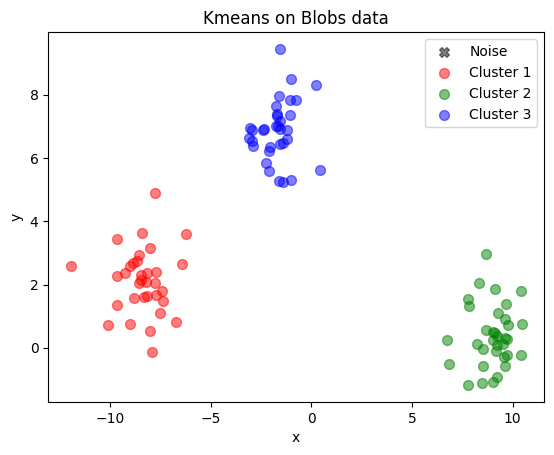



Running Dbscan on Moons data...

Labels: [0 0 1 1 0 1 0 1 0 1 0 1 0 1 1 1 1 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 1 1 1 1
 1 0 0 1 0 1 1 0 1 0 0 1 0 0 1 1 0 1 1 1 0 0 0 1 1 0 0 1 0 1 0 0 0 1 1 1 0
 1 1 1 0 1 0 1 0 1 1 1 0 1 1 1 0 0 1 1 0 0 0 0 1 0 0]

Confusion Matrix: 
[[ 0 50]
 [50  0]]


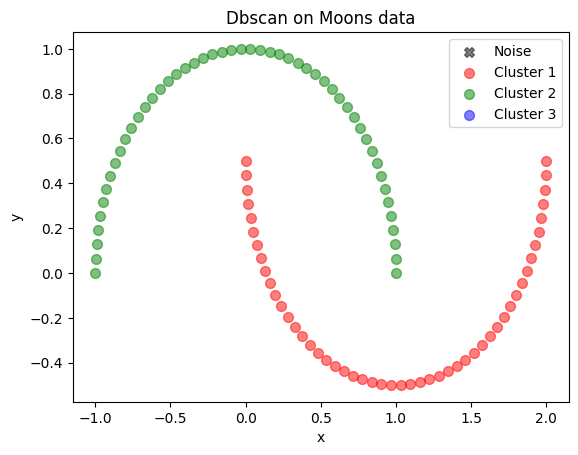



Running Agglomerativa on Circles data...

Labels: [1 1 0 2 0 1 1 1 0 2 0 2 0 1 0 1 0 0 0 1 1 1 1 0 2 1 0 1 1 0 0 1 1 0 1 0 1
 1 2 0 1 2 2 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 2 1 1 1 1 0 1 0 1 0 0 0 1 0 1
 1 0 1 0 0 1 1 0 0 2 0 1 0 1 1 0 0 1 1 2 1 1 0 1 1 1]

Confusion Matrix: 
[[40  0 10]
 [ 0 50  0]
 [ 0  0  0]]


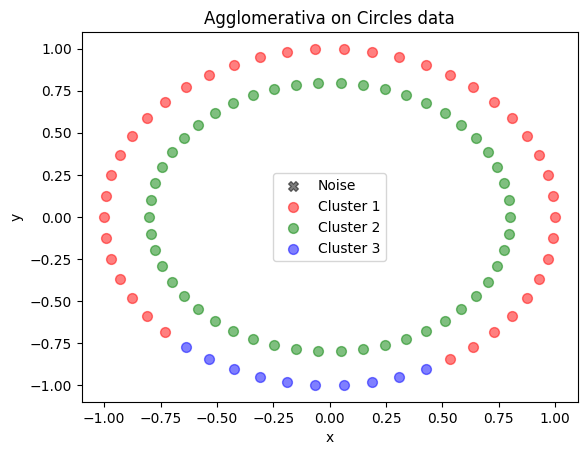

In [76]:
for (data_name, (X, y)), (algo_name, algorithm) in zip(datas.items(), algorithms.items()):
        print (f'\n\nRunning {algo_name} on {data_name} data...')

        label = algorithm.fit_predict(X)
        result = confusion_matrix(y, label)

        print(f'\nLabels: {label}')
        print(f'\nConfusion Matrix: \n{result}')

        plot_clusters(X, label, f'{algo_name} on {data_name} data')

        print("===" * 200)

### Biulding the hierachical dendrogram:

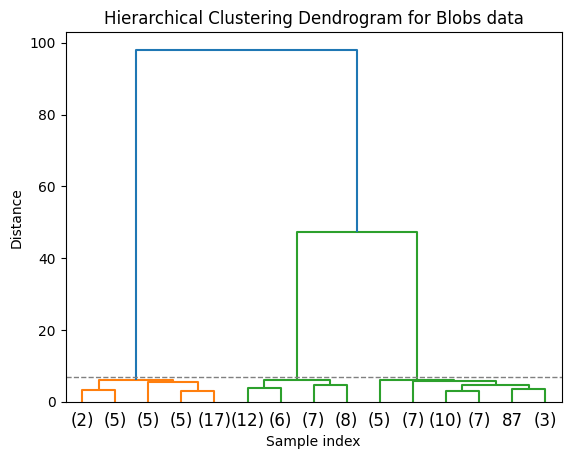

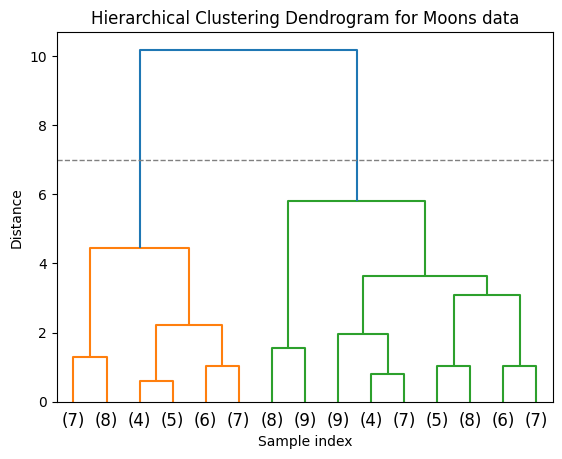

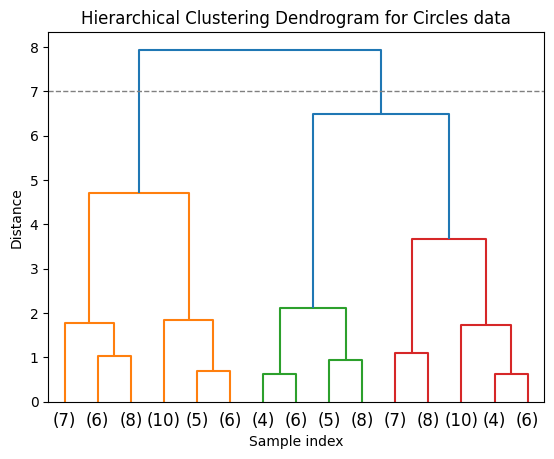

In [77]:
for data_name, (data, _) in datas.items():
    plt.Figure(figsize = (8, 6))
    plt.title(f'Hierarchical Clustering Dendrogram for {data_name} data')
    plt.xlabel('Sample index')
    plt.ylabel('Distance')

    linkage_matrix = linkage(data.data, method = 'ward')

    dendrogram(linkage_matrix, truncate_mode = 'lastp', p = 15)

    plt.axhline( y = 7, c = 'gray', lw = 1, linestyle = 'dashed')

    plt.show()